In [12]:
# Imports
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
%matplotlib inline
import sklearn
import pandas as pd
from scipy import signal
import seaborn as sns

import netCDF4 as nc
from netCDF4 import Dataset
import xarray as xr

import tigramite
from tigramite import data_processing as pp
from tigramite.toymodels import structural_causal_processes as toys
from tigramite import plotting as tp
from tigramite.pcmci import PCMCI
from tigramite.lpcmci import LPCMCI

from tigramite.independence_tests.parcorr import ParCorr
from tigramite.independence_tests.robust_parcorr import RobustParCorr
from tigramite.independence_tests.gpdc import GPDC
from tigramite.independence_tests.cmiknn import CMIknn

from tigramite.models import LinearMediation, Prediction

### define functions

In [13]:
def bootstrap_df(data, n_iterations=100, n_omit=5):

    bootstrapped_dataframes = []
    
    # Extract unique years from the data index
    years = data.index.year.unique()
    
    for _ in range(n_iterations):
        # Select random years to omit
        omit_years = np.random.choice(years, n_omit, replace=False)
        
        # Create a mask for the rows to keep
        mask = ~data.index.year.isin(omit_years)
        
        # Subset the data
        bootstrapped_sample = data[mask]
        
        # Append the bootstrapped sample to the list
        bootstrapped_dataframes.append(bootstrapped_sample)
    
    return bootstrapped_dataframes

In [14]:
def getgraph_fixed(df, indices, index_selection, all_parents, tau_min, tau_max):

    CE = []
    df = df
    
    test = df[indices]
    index_selection = index_selection
    
    data = np.array(test)
    
    mask_key = 'Southern AR dry season'
    mask = df[[f'{mask_key}', f'{mask_key}', f'{mask_key}', f'{mask_key}']]
    data_mask = np.array(mask)
    
    T, N = data.shape
    # Initialize dataframe object, specify time axis and variable names
    names = index_selection
    dataframe = pp.DataFrame(data, 
                         mask=data_mask,
                         datatime = {0:np.arange(len(data))}, 
                         var_names=names)

    med = LinearMediation(dataframe=dataframe,
            mask_type = 'y')
    med.fit_model(all_parents = all_parents, tau_max=tau_max) 
    Links = med.get_val_matrix()
    return med

## Bootstrapping

In [15]:
path = '/Users/ernest/Research/thesis/_paper_/'

In [16]:
df = pd.read_csv(path + 'data/ERA5_1982-2022.csv', index_col=[0])
df['time'] = pd.to_datetime(df['time'])
df.set_index('time', inplace=True)

In [17]:
# prescribe links from main network

all_parents = {0: [(0, -1)], 
 1: [(1, -1), (1, -2), (0, -2)], 
 2: [(1, -1), (0, -2)], 
 3: [(3, -1), (2, -1)]}

In [18]:
boots = bootstrap_df(df, n_iterations=500, n_omit=5)

In [19]:
variables = ['AMOC_era5', 'CLLJ', 'SAR_prec', 'NDVI']
index_selection = ['AMOC', 'CLLJ', 'PREC', 'NDVI']

AMOC_CLLJ = []
CLLJ_PREC = []
AMOC_PREC = []
AMOC_PREC_t = []
PREC_NDVI = []
AMOC_NDVI = []
Auto_AMOC = []
Auto_CLLJ = []
Auto_PREC = []
Auto_NDVI = []

for i, data in enumerate(boots):
    med = getgraph_fixed(data, variables, index_selection, all_parents, 0, 5)
    AMOC_CLLJ.append(med.get_ce(i=0, tau=-2, j=1))
    CLLJ_PREC.append(med.get_ce(i=1, tau=-1, j=2))
    AMOC_PREC.append(med.get_ce(i=0, tau=-2, j=2))
    AMOC_PREC_t.append(med.get_ce(i=0, tau=-3, j=2))
    PREC_NDVI.append(med.get_ce(i=2, tau=-1, j=3))
    AMOC_NDVI.append(med.get_ce(i=0, tau=-4, j=3))
    Auto_AMOC.append(med.get_ce(i=0, tau=-1, j=0))
    Auto_CLLJ.append(med.get_ce(i=1, tau=-2, j=1))
    Auto_PREC.append(med.get_ce(i=2, tau=-1, j=2))
    Auto_NDVI.append(med.get_ce(i=3, tau=-4, j=3))

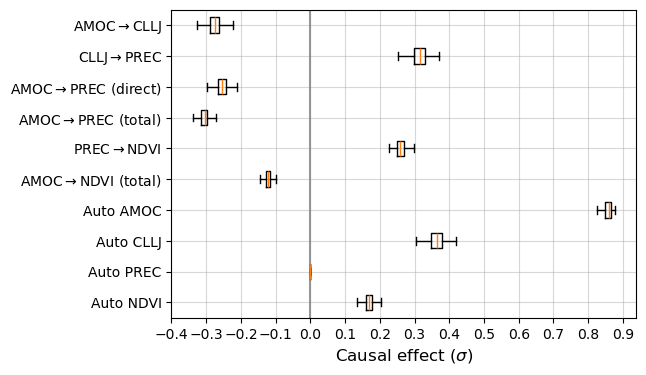

In [20]:
plt.figure(figsize=(6,4))
flierprops = dict(marker='o', markerfacecolor='k', markersize=6, markeredgecolor='none', alpha=.5)
plt.boxplot([Auto_NDVI, Auto_PREC, Auto_CLLJ, Auto_AMOC, AMOC_NDVI, PREC_NDVI, AMOC_PREC_t, AMOC_PREC, CLLJ_PREC, AMOC_CLLJ], 
            labels=['Auto NDVI', 'Auto PREC', 'Auto CLLJ', 'Auto AMOC', r'AMOC$\rightarrow$NDVI (total)',
                    r'PREC$\rightarrow$NDVI', r'AMOC$\rightarrow$PREC (total)', r'AMOC$\rightarrow$PREC (direct)', 
                    r'CLLJ$\rightarrow$PREC', r'AMOC$\rightarrow$CLLJ'], vert=False, showfliers=False, flierprops=flierprops)
plt.axvline(x=0, color='grey', alpha=.8)
plt.yticks(fontsize=10)
x_ticks = np.arange(-0.4, 1, 0.1)
plt.xticks(x_ticks, fontsize=10)
plt.xlabel(r'Causal effect ($\sigma$)', fontsize=12)
plt.tick_params(axis='x', bottom=True)
plt.grid(alpha=.5)
plt.savefig(path + 'figures/Figure_3b.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [21]:
df = pd.DataFrame({'AMOC_CLLJ': AMOC_CLLJ, 'CLLJ_PREC': CLLJ_PREC, 'AMOC_PREC': AMOC_PREC,
                  'AMOC_PREC_t': AMOC_PREC_t, 'PREC_NDVI': PREC_NDVI, 'AMOC_NDVI': AMOC_NDVI})
df

,AMOC_CLLJ,CLLJ_PREC,AMOC_PREC,AMOC_PREC_t,PREC_NDVI,AMOC_NDVI
0,-0.274944,0.298981,-0.283256,-0.327597,0.258059,-0.130835
1,-0.277598,0.324233,-0.236144,-0.293150,0.248194,-0.109874
2,-0.253974,0.287366,-0.249797,-0.288087,0.255290,-0.115314
3,-0.271742,0.310098,-0.246539,-0.296045,0.263705,-0.119866
4,-0.274102,0.307099,-0.235234,-0.286190,0.279904,-0.123314
...,...,...,...,...,...,...
495,-0.272333,0.320281,-0.240594,-0.289606,0.277207,-0.121875
496,-0.255764,0.328288,-0.234086,-0.284053,0.270284,-0.117640
497,-0.258824,0.343169,-0.286143,-0.328808,0.250460,-0.127628
498,-0.234237,0.302024,-0.257167,-0.289617,0.285314,-0.130108


In [22]:
stats = df.describe()
print(stats)

        AMOC_CLLJ   CLLJ_PREC   AMOC_PREC  AMOC_PREC_t   PREC_NDVI   AMOC_NDVI
count  500.000000  500.000000  500.000000   500.000000  500.000000  500.000000
mean    -0.276174    0.314850   -0.254629    -0.304937    0.259829   -0.121625
std      0.019314    0.024077    0.016871     0.013948    0.014558    0.009154
min     -0.337313    0.249922   -0.317153    -0.358550    0.225410   -0.148587
25%     -0.289588    0.299188   -0.266334    -0.313810    0.249795   -0.127527
50%     -0.275731    0.316133   -0.254472    -0.304647    0.257869   -0.120859
75%     -0.262618    0.330981   -0.243557    -0.296395    0.269988   -0.115036
max     -0.222565    0.379188   -0.206258    -0.265476    0.310682   -0.096085
